In [12]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

In [13]:
df = pd.read_csv("TempNY.csv")
df = df.drop("Unnamed: 2", axis=1)
df.index = df["Year"]
df = df.drop("Year", axis=1)

In [14]:
df.index = pd.PeriodIndex(df.index, freq="Y")

In [16]:
#Split 90/10
len_train = int(len(df) * 0.9)
train = df.iloc[:len_train]
test  = df.iloc[len_train:]
print(len(train), len(test))

135 16


In [17]:
#ADF sobre train
result = adfuller(train["Average"])
print("El valor p de la prueba de Dickey-Fuller es:", result[1])

El valor p de la prueba de Dickey-Fuller es: 0.42201206191180785


In [19]:
#ADF sobre las diferencias
train_diff = train["Average"].diff().dropna()
result2 = adfuller(train_diff)
print("El valor p de la prueba de Dickey-Fuller es:", result2[1])

El valor p de la prueba de Dickey-Fuller es: 1.5713108896118464e-13


### Busqueda del módelo óptimo

In [20]:
combinaciones = [
    (0,1,0), (0,1,1), (1,1,0),
    (1,1,1), (2,1,1), (1,1,2),
    (2,1,2), (0,1,2),
]

resultados = []
for order in combinaciones:
    try:
        m = ARIMA(train["Average"], order=order).fit()
        resultados.append((order, m.aic, m.bic))
    except Exception:
        resultados.append((order, np.nan, np.nan))

tabla = pd.DataFrame(resultados, columns=["Orden (p,d,q)", "AIC", "BIC"]).sort_values("AIC")
print(tabla.to_string(index=False))

D:\anaconda3\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:966: UserWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  warn('Non-stationary starting autoregressive parameters'
D:\anaconda3\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:978: UserWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  warn('Non-invertible starting MA parameters found.'
D:\anaconda3\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:966: UserWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  warn('Non-stationary starting autoregressive parameters'
D:\anaconda3\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:978: UserWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  warn('Non-invertible starting MA parameters found.'


Orden (p,d,q)        AIC        BIC
    (0, 1, 1) 433.656509 439.452189
    (1, 1, 1) 435.230115 443.923635
    (0, 1, 2) 435.279607 443.973127
    (2, 1, 2) 436.813381 451.302580
    (2, 1, 1) 436.824147 448.415506
    (1, 1, 2) 437.025876 448.617235
    (1, 1, 0) 462.295330 468.091010
    (0, 1, 0) 496.475203 499.373043


In [21]:
#Ajuste del modelo optimo sobre train
mod = ARIMA(train["Average"], order=(0,1,1))
res = mod.fit()
print(res.summary())

                               SARIMAX Results                                
Dep. Variable:                Average   No. Observations:                  135
Model:                 ARIMA(0, 1, 1)   Log Likelihood                -214.828
Date:                Tue, 20 Oct 2026   AIC                            433.657
Time:                        13:40:56   BIC                            439.452
Sample:                    12-31-1870   HQIC                           436.012
                         - 12-31-2004                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ma.L1         -0.8538      0.050    -17.078      0.000      -0.952      -0.756
sigma2         1.4316      0.211      6.780      0.000       1.018       1.845
Ljung-Box (L1) (Q):                   0.25   Jarque-

In [22]:
#Pronosticos sobre test
forecast = res.get_forecast(steps=len(test))
pred_mean = forecast.predicted_mean
pred_ci   = forecast.conf_int(alpha=0.05)

pred_mean.index = test.index
pred_ci.index   = test.index

print(pred_mean)
print(pred_ci)

Year
2005    55.098228
2006    55.098228
2007    55.098228
2008    55.098228
2009    55.098228
2010    55.098228
2011    55.098228
2012    55.098228
2013    55.098228
2014    55.098228
2015    55.098228
2016    55.098228
2017    55.098228
2018    55.098228
2019    55.098228
2020    55.098228
Freq: Y-DEC, Name: predicted_mean, dtype: float64
      lower Average  upper Average
Year                              
2005      52.753172      57.443284
2006      52.728232      57.468224
2007      52.703551      57.492905
2008      52.679123      57.517333
2009      52.654938      57.541518
2010      52.630990      57.565466
2011      52.607273      57.589183
2012      52.583780      57.612676
2013      52.560503      57.635953
2014      52.537439      57.659017
2015      52.514580      57.681876
2016      52.491922      57.704534
2017      52.469459      57.726997
2018      52.447187      57.749269
2019      52.425100      57.771356
2020      52.403194      57.793262


### Grafica

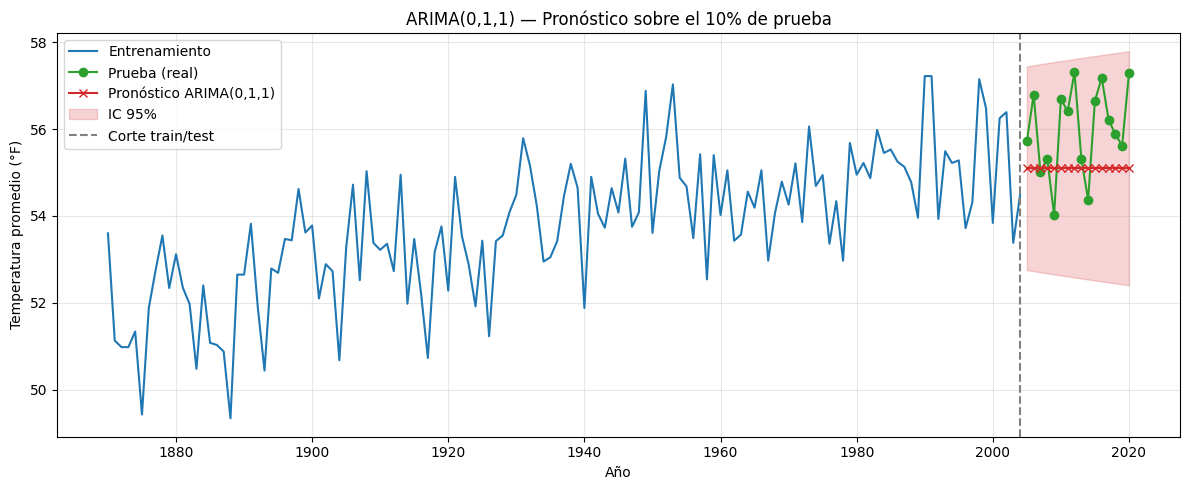

In [24]:
plt.figure(figsize=(12,5))
plt.plot(train.index.to_timestamp(), train["Average"],label="Entrenamiento", color="tab:blue")
plt.plot(test.index.to_timestamp(), test["Average"],label="Prueba (real)", color="tab:green", marker="o")
plt.plot(pred_mean.index.to_timestamp(), pred_mean,label="Pronóstico ARIMA(0,1,1)", color="tab:red", marker="x")
plt.fill_between(pred_ci.index.to_timestamp(),pred_ci.iloc[:,0], pred_ci.iloc[:,1],color="tab:red", alpha=0.2, label="IC 95%")
plt.axvline(train.index[-1].to_timestamp(), color="gray",linestyle="--", label="Corte train/test")
plt.xlabel("Año"); plt.ylabel("Temperatura promedio (°F)")
plt.title("ARIMA(0,1,1) — Pronóstico sobre el 10% de prueba")
plt.legend();
plt.grid(alpha=0.3); 
plt.tight_layout(); 
plt.show()

In [25]:
y_true = test["Average"].values
y_pred = np.asarray(pred_mean)

rmse = np.sqrt(np.mean((y_true - y_pred)**2))
mape = np.mean(np.abs((y_true - y_pred) / y_true)) * 100

print(f"RMSE = {rmse:.2f} °F")
print(f"MAPE = {mape:.2f} %")

RMSE = 1.32 °F
MAPE = 1.99 %
